<a href="https://colab.research.google.com/github/MFerrugem/RNA/blob/main/vgg16_tensorflow2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação de imagens com VGG16 pré-treinada (TensorFlow 2.x)

Notebook adaptado do código de Sreenivas Bhattiprolu (*Python for Microscopists*, https://youtu.be/LOvrfvtiC8c). Reutilização livre, com atribuição ao autor original.

**Principais adaptações para TensorFlow 2.x**
- Imports via `tensorflow.keras` (em vez do pacote `keras` isolado).
- `decode_predictions` importado de `vgg16`, o mesmo módulo do modelo. O original importava de `mobilenet`; o resultado é o mesmo (as duas usam o índice ImageNet), mas assim fica consistente.
- Caminho da imagem configurável, com download de uma imagem de exemplo caso o arquivo não exista.

**Fluxo:** carregar o modelo → carregar e preparar a imagem → pré-processar → prever → mostrar as 5 classes mais prováveis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing.image import load_img, img_to_array

print("TensorFlow:", tf.__version__)
print("GPUs disponíveis:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs disponíveis: []


## 1. Carregar o modelo VGG16

Na primeira execução os pesos (cerca de 500-600 MB) são baixados da internet e ficam em cache em `~/.keras/models`. Por padrão `VGG16()` carrega a rede completa, com pesos ImageNet e 1000 classes de saída.

In [2]:
model = VGG16(weights="imagenet")
model.summary()

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

## 2. Carregar a imagem de teste

O VGG16 exige entrada **224 x 224 x 3**. Defina em `IMAGE_PATH` o caminho da sua imagem. Se o arquivo não existir, uma imagem de exemplo é baixada.

'images/cab.jpg' não encontrado. Baixando imagem de exemplo...
83281/83281 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


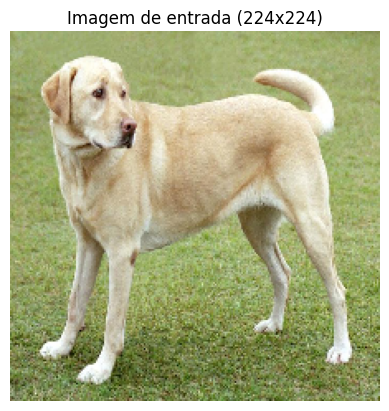

In [3]:
import os

IMAGE_PATH = "images/cab.jpg"   # altere para a sua imagem

if not os.path.exists(IMAGE_PATH):
    print(f"'{IMAGE_PATH}' não encontrado. Baixando imagem de exemplo...")
    IMAGE_PATH = tf.keras.utils.get_file(
        "exemplo.jpg",
        "https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_new.jpg",
    )

img = load_img(IMAGE_PATH, target_size=(224, 224))
plt.imshow(img)
plt.axis("off")
plt.title("Imagem de entrada (224x224)")
plt.show()

## 3. Preparar e pré-processar

1. Converter os pixels para array NumPy.
2. Adicionar a dimensão de lote: o modelo espera `(n_imagens, 224, 224, 3)`, então a entrada vira `(1, 224, 224, 3)`.
3. Aplicar `preprocess_input`, o mesmo pré-processamento do treino (subtrai a média RGB do ImageNet e converte RGB para BGR).

In [4]:
x = img_to_array(img)               # (224, 224, 3)
x = np.expand_dims(x, axis=0)       # (1, 224, 224, 3)
x = preprocess_input(x)

print("Formato da entrada:", x.shape)

Formato da entrada: (1, 224, 224, 3)


## 4. Predição

O modelo devolve um vetor com a probabilidade de cada uma das 1000 classes do ImageNet. `decode_predictions` converte os índices em nomes e retorna as 5 melhores.

In [5]:
pred = model.predict(x)
top5 = decode_predictions(pred, top=5)[0]

for class_id, label, prob in top5:
    print(f"{label:<25} {prob*100:6.2f}%   ({class_id})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Labrador_retriever         35.92%   (n02099712)
golden_retriever           21.88%   (n02099601)
Chesapeake_Bay_retriever    4.86%   (n02099849)
kuvasz                      4.79%   (n02104029)
redbone                     3.90%   (n02090379)


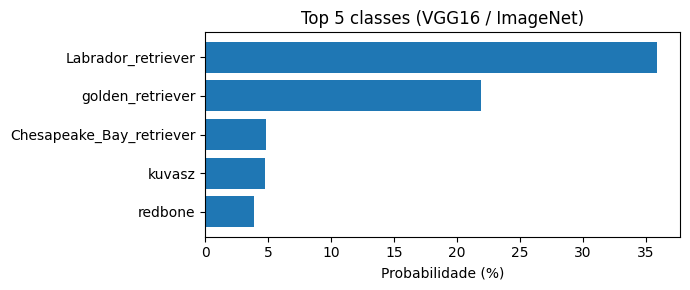

In [6]:
# Visualização das 5 classes mais prováveis
labels = [t[1] for t in top5][::-1]
probs = [t[2] * 100 for t in top5][::-1]

plt.figure(figsize=(7, 3))
plt.barh(labels, probs)
plt.xlabel("Probabilidade (%)")
plt.title("Top 5 classes (VGG16 / ImageNet)")
plt.tight_layout()
plt.show()

## Próximos passos (transfer learning)

Para reaproveitar a VGG16 em outro problema, carregue sem a camada de classificação e congele a base:

```python
base = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False
```

Depois acrescente suas próprias camadas (`GlobalAveragePooling2D` + `Dense`) e treine com seu conjunto de dados.